# MU4MA015, Statistique, 2023-2024

Sorbonne Université, Master 1

Cours :  A. Ben-Hamou <br>
TP : A. Godichon, A. Guyader et M. Sangnier

## TP 1 : Statistique fréquentiste

# Table of contents
1. [Exercice 1 : Lois classiques](#part1)
1. [Exercice 2 : Loi des Grands Nombres](#part2)
1. [Exercice 3 : Théorème Central Limite](#part3)
1. [Exercice 4 : Régression linéaire simple](#part4)
1. [Exercice 5 : Convergence en loi](#part5)
1. [Exercice 6 : Comparaison d'estimateurs](#part6)
1. [Exercice 7 : Fonction de répartition empirique](#part7)
    - [Exercice 8 : Estimateur, test et fonction puissance](#part7sec1)


In [1]:
import numpy as np  # Vectors and matrices
from scipy import stats  # Probability distributions
import statsmodels.api as sm  # Linear regression
from statsmodels.sandbox.regression.predstd import wls_prediction_std  # Linear regression
import matplotlib.pyplot as plt  # Plots
from matplotlib import style
style.use('seaborn')  # Enable nice plots

/tmp/ipykernel_26270/2106305277.py:7: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  style.use('seaborn')  # Enable nice plots


# Exercice 1 : Lois classiques <a id="part1"></a>
>**Question 1.**
Afficher sur le même graphique les densités des lois $\chi^2_{50}$ et $\mathcal{N}(50,100)$.
On prendra soin d'agrémenter la figure de toutes les indications utiles (titre, légende…).
>
>Que constatez-vous ? Comment pouvez-vous le justifier ?

In [ ]:
# Answer
ddl = 50

chi2 = stats.chi2(df=ddl)
norm = stats.norm(loc=ddl, scale=np.sqrt(2*ddl))

x = np.arange(0, 2*ddl, step=0.1)

plt.plot(x, chi2.pdf(x), label=f"$\\chi^2_{{{ddl}}}$")
# Compléter

# Fin compléter
plt.title("Loi normale et loi du khi-deux");

**Réponse :**
…

>**Question 2.**
Afficher sur le même graphique les densités des lois $\mathcal{T}_{5}$, $\mathcal{T}_{30}$ et $\mathcal{N}(0,1)$.
>
>Que constatez-vous ? Comment pouvez-vous le justifier ?

In [ ]:
# Answer
d1 = 5
d2 = 30

t1 = stats.t(df=d1)
t2 = stats.t(df=d2)
# Compléter

# Fin compléter
plt.title("Loi normale et lois de Student");

**Réponse :**
…

>**Question 3.**
Afficher sur le même graphique les densités de la loi de Fisher $\mathcal{F}^3_{20}$ et d'un $\frac{\chi_3^2}{3}$. On rappelle que si $X$ suit une loi avec les paramètres par défaut, alors la variable $Y=$ `scale` $X$+`loc`suit la loi dilatée translatée. 
>
>Que constatez-vous ? Comment pouvez-vous le justifier ?

In [ ]:
# Answer
d1 = 3
d2 = 20

f = stats.f(d1, d2)
# Compléter

# Fin compléter
plt.plot(x, chi.pdf(x), label=f"$\\frac{{\\chi^2_{{{d1}}}}}{{{d1}}}}}$")
plt.legend()
plt.xlabel('x')
plt.ylabel('Densité')
plt.title("Loi de Fisher et loi du khi-deux");

**Réponse :**
…

# Exercice 2 : Loi des Grands Nombres <a id="part2"></a>
>**Question 1.**
Illustrer la Loi des Grands Nombres sur la loi Beta de paramètres $(\alpha, \beta) = (2, 5)$. Indication : pour calculer les moyennes successives, on pourra utiliser la fonction `cumsum`.

In [ ]:
# Answer
dist = stats.beta(a=2, b=5)
print("Support de la loi Beta :", dist.support())

x = np.linspace(0, 1)
plt.plot(x, dist.pdf(x))
plt.title("Densité")

n = 5000
X = dist.rvs(size=n)
fig = plt.figure()

# Compléter

# Fin compléter
plt.axhline(dist.mean(), color='red', label="$\\mathbb{{E}} [X_1]$")
plt.xlabel('n')
plt.legend();

Exemple :

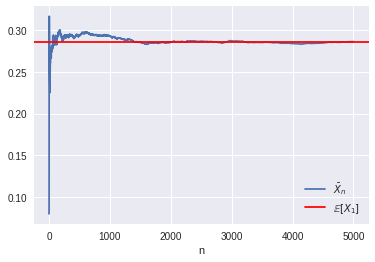

In [6]:
fig

In [ ]:
# Answer

>**Question 2.**
Faire de même avec la loi de Cauchy. On tracera plusieurs trajectoires.

In [ ]:
# Answer
dist = stats.cauchy()
print("Support de la loi de Cauchy :", dist.support())

x = np.linspace(-10, 10, num=200)
plt.plot(x, dist.pdf(x))
plt.title("Densité")

N, n = 5, 5000
X = dist.rvs(size=(N, n))
# Compléter

# Fin compléter

# Exercice 3 : Théorème Central Limite <a id="part3"></a>
> Afficher la densité de probabilité de la loi Beta de paramètres $\alpha=0.5$ et $\beta=0.5$,
puis illustrer le Théorème Central Limite à l'aide d'histogrammes.
>
>On rappelle qu'un histogramme est un estimateur de la densité et que le lemme de Scheffé assure que la convergence simple des densités implique la convergence en loi.
>
>**Lemme de Scheffé**
>>Soient $(X_n)_{n\ge 1}$ une suite de variables aléatoires de densités $(f_n)_{n\ge 1}$ par rapport à une mesure dominante $\mu$
et $X$ une variable aléatoire de densité $f$ par rapport à $\mu$.
Si $(f_n)_{n\ge 1}$ converge simplement $\mu$-presque partout vers $f$, alors
$$
X_n \underset{n \to \infty}{\overset{\mathcal{L}}{\longrightarrow}} X.
$$

In [ ]:
# Answer
dist = stats.beta(a=.5, b=.5)
norm = stats.norm()

x = np.linspace(0, 1, num=200)
plt.plot(x, dist.pdf(x))
plt.title("Densité")

N = 100000
x = np.linspace(-3, 3)

fig_hist = plt.figure(figsize=(15, 15))
for i, n in enumerate([1, 5, 10, 50]):
    # Compléter

    # Fin compléter
    
    plt.subplot(2, 2, i+1)
    plt.hist(rv, bins='auto', density=True, label="Histogramme de $\\sqrt{{n}}\\ \\frac{{\\bar{{X}}_n - \\mathbb{{E}}[X_1]}}{{\\sigma}}$")  # normed=True for old versions
    plt.plot(x, norm.pdf(x), label="Densité de $\\mathcal{{N}}(0, 1)$")
    plt.legend()
    plt.title("$n = %d$" % n)

Exemple :

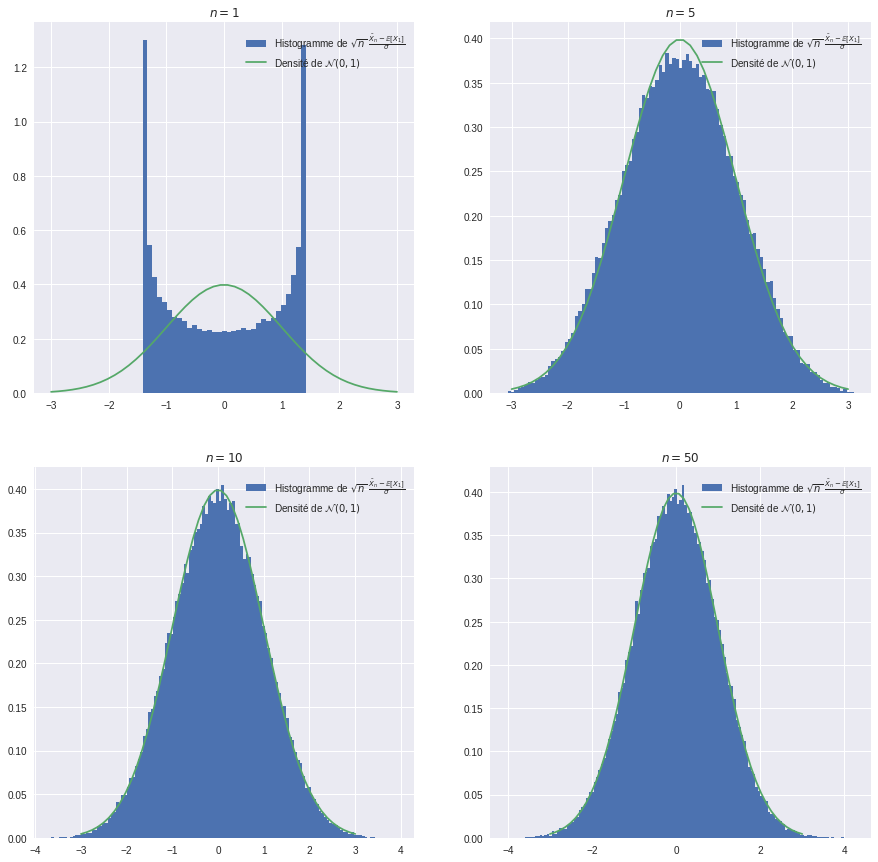

In [10]:
fig_hist

# Exercice 4 : Régression linéaire simple <a id="part4"></a>
>Considérons le modèle définissant, pour tout $i \in \{1, \dots, n\}$, les observations $$Y_i = a + b t_i  + \varepsilon_i,$$ où $t_1, \dots, t_n$ sont des données figées, $\varepsilon_1, \dots, \varepsilon_n$ sont des variables aléatoires i.i.d. de loi $\mathcal{N}(0, \sigma^2)$.
On cherche à estimer les paramètres inconnus $\beta=(a, b)$ et $\sigma^2$.

In [11]:
# Generate data
n = 50
t = np.linspace(0, 10, n)
X = np.column_stack((np.ones((n)),t))

beta = [2, -1]
y_true = X @ beta 

sigma = 2
noise = stats.norm(scale=sigma)
y = y_true + noise.rvs(size=n)

>**Question 1.**
Afficher en fonction de $(t_i)_{1 \le i \le n}$ les observations $(Y_i)_{1 \le i \le n}$ et la « vraie » droite $y = a + b t$.

In [ ]:
# Answer
# Compléter

# Fin compléter
plt.xlabel('t')
plt.ylabel('y')
plt.legend();

>**Question 2.**
Résoudre le problème de régression linéaire avec la routine `sm.OLS` et afficher le tableau de résultats.

In [ ]:
# Answer
# Compléter

# Fin compléter
res.summary()

>**Question 3.**
Retrouver par le calcul les valeurs des réalisations des estimateurs des moindres carrés $\hat \beta$ et $\hat \sigma_n^2$ donnés ci-dessus, c'est-à-dire :

In [14]:
print("Estimateur beta :", res.params)
print("Estimateur sigma2 :", res.scale)

Estimateur beta : [ 1.73964941 -0.88044176]
Estimateur sigma2 : 4.671719824372725


In [ ]:
# Answer
inv = np.linalg.inv(X.T @ X)
# Compléter

# Fin compléter

print("Estimateur beta :", hat_beta)
print("Estimateur sigma2 :", hat_sigma2)

>**Question 4.**
Ajouter sur le graphe précédent la droite estimée $y=\hat{a}+\hat{b}t$.

In [ ]:
# Answer
# Compléter

# Fin compléter
plt.xlabel('t')
plt.ylabel('y')
plt.legend();

>**Question 5.**
Calculer et ajouter à la figure l'hyperbole de prédiction au niveau $(1-\alpha)$ pour $\alpha = 5\%$.

In [ ]:
# Answer
stu = stats.t(n-2)
q = stu.ppf(1-0.05/2)
# Compléter

# Fin compléter
plt.xlabel('t')
plt.ylabel('y')
plt.legend();

# Exercice 5 : Convergence en loi <a id="part5"></a>
> On considère une suite de variables aléatoires $(X_i)_{i\geq 1}$ i.i.d. suivant une loi exponentielle de paramètre 1 et, pour tout $n$, on note $M_n:=X_{(n)}-\log n$ avec comme d'habitude $X_{(n)}:=\max_{1\leq i\leq n}X_i$. Grâce au critère des fonctions de répartition, illustrer numériquement le fait que $M_n$ converge en loi vers une loi de Gumbel de fonction de répartition $F(x)=\exp(-\exp(-x))$. 

**Réponse :**
…

In [ ]:
# Answer
n = 10
x = np.linspace(-3, 5, num=200)
# Compléter

# Fin compléter
plt.legend()
plt.xlabel('x')
plt.ylabel('Fonction de répartition')
plt.title("Convergence en loi de $M_n$ vers une loi de Gumbel");

# Exercice 6 : Comparaison d'estimateurs <a id="part6"></a>
>Soit $X$ une variable aléatoire réelle de densité $f_{\theta^\star}$, où $\theta^\star \in \mathbb R_+^*$ est inconnu et pour tout $\theta > 0$,
$$f_\theta : x \in \mathbb R \mapsto \frac{1}{\theta} \exp \left( -\frac{x-\theta}{\theta} \right) \mathbb 1_{[\theta, +\infty[}(x).$$
$X$ suit donc une loi exponentielle translatée de $\theta^\star$ et dilatée de $\theta^\star$.
Autrement dit, $\frac{X-\theta^\star}{\theta^\star} \sim \mathcal{E}(1)$.
>
>On suppose que l'on dispose d'un $n$-échantillon $\mathbf X = (X_1, \dots, X_n)$ dont les variables aléatoires sont distribuées identiquement à $X$.
Soient les trois estimateurs suivants de $\theta^\star$:
$$
		T_{1, n}(\mathbf X) = \frac{1}{2n} \sum_{i=1}^n X_i,
		\qquad
		T_{2, n}(\mathbf X) = \frac{x_{1/2}(n)}{1+\ln(2)} % x_{1/2}(n)
		\quad \text{et} \quad
		T_{3, n}(\mathbf X) = \min_{1 \le i \le n} X_i,
$$
où $x_{1/2}(n)$ est la médiane empirique de  $\mathbf X$.
>
>**Question 1.**
Pour les illustrations numériques, considérons que le paramètre inconnu vaut $\theta^\star=4$.
Tracer la densité de $X$.
Afficher l'espérance et la variance de $X$ et vérifier que les résultats sont cohérents avec les valeurs théoriques.

In [ ]:
# Answer
from scipy.stats import expon

theta = 4.
# Compléter

# Fin compléter
plt.title(f'Densité de la loi exponentielle translatée de {theta} et dilatée de {theta}');

In [ ]:
# Answer

>**Question 2.**
Considérons que $n=200$.
Tirer aléatoirement un échantillon de taille $n$ selon la loi de $X$ et calculer les réalisations des trois estimateurs.
Afficher leurs valeurs.
>
>Indication : la médiane empirique d'un échantillon $\mathbf X$ s'obtient par la commande `np.quantile(X, 0.5, interpolation='lower')` ou `np.percentile(x, 50, interpolation='lower')`.

In [ ]:
# Answer

>**Question 3.**
Soit $N=1000$.
Tirer aléatoirement $N$ échantillons $\mathbf X_1, \dots, \mathbf X_N$ de taille $n$ de manière indépendante et identiquement distribuée à $\bf X$.
Calculer puis afficher une estimation du risque quadratique de chacun des trois estimateurs $T_{k, n}$ ($k \in \{1, 2, 3\}$) :
$$
    R_{k, n} = \frac{1}{N} \sum_{j=1}^N (T_{k, n}(\mathbf X_j) - \theta^\star)^2.
$$

In [ ]:
# Answer

>**Question 4.**
Répéter cette opération pour plusieurs valeurs de $n$ comprises entre 10 et 200 puis afficher (avec une échelle logarithmique en x et y) l'évolution du risque quadratique estimé $R_{k, n}$ ($k \in \{1, 2, 3\}$) en fonction de $n$.
Quel estimateur vous semble préférable ?

In [ ]:
# Answer

# Exercice 7 : Fonction de répartition empirique <a id="part7"></a>
> On considère une suite de variables aléatoires $(X_i)_{i\geq 1}$ i.i.d. suivant une loi de Cauchy dont la fonction de répartition est notée $F$. Pour tout $n\geq 1$ et tout réel $x$, on considère la fonction de répartition empirique 
$$F_n(x):=\frac{1}{n}\sum_{i=1}^n\mathbf{1}_{X_i\leq x}.$$
Illustrer la convergence de $F_n$ vers $F$. On pourra utiliser la classe `ECDF` du module `statsmodels.distributions.empirical_distribution`.

In [ ]:
# Answer
from statsmodels.distributions.empirical_distribution import ECDF

n = 20
dist = stats.cauchy()

# Compléter

# Fin compléter
plt.xlabel('x')
plt.legend()
plt.title("Loi de Cauchy : Fonctions de répartition empirique et théorique");

In [ ]:
# Answer

## Exercice 8 : Estimateur, test et fonction puissance <a id="part7sec1"></a>
>**Question 1.**
Soient $\theta = 2$ et $(X_1, \dots, X_n)$ un $n$-échantillon distribué selon $\mathcal{E}(\theta)$.
On suppose $n=50$.
Générer une réalisation de $(X_1, \dots, X_n)$.
Afficher un histogramme de cette réalisation et superposer la densité de probabilité.

In [ ]:
# Answer

>**Question 2.**
Donner un estimateur $\hat \theta_n$ de $\theta$ par la méthode des moments et calculer sa réalisation.

**Réponse :**
…

In [ ]:
# Answer

>**Question 2.**
On souhaite tester $H_0 : \theta = 1$ contre $H_1 : \theta \neq 1$.
Construire un test de niveau asymptotique $\alpha$ (avec $\alpha = 5\%$) pour les hypothèses précédentes.
Afficher sa réalisation et la $p$-valeur associée.
Conclure.

**Réponse :**
…

In [ ]:
# Answer

>**Question 3.**
Pour $n$ grand, calculer et représenter une approximation de la fonction puissance $\pi_n(\theta)$ associée à ce test pour $\theta$ variant entre 0 et 5.

**Réponse :**
…

In [ ]:
# Answer

>**Question 4.**
Que se passe-t-il lorsque $n$ grandit ?

In [ ]:
# Answer

**Réponse :**
…